Current notebook directory:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\notebooks

Project root:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection

Data root:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw

Training directory:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Training

Testing directory:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Testing

Classes:
['glioma', 'meningioma', 'notumor', 'pituitary']

Number of classes:
4

Training image counts:
----------------------------------------
glioma         : 1400
meningioma     : 1400
notumor        : 1400
pituitary      : 1400

Testing image counts:
----------------------------------------
glioma         : 400
meningioma     : 400
notumor        : 400
pituitary      : 400

Dataset distribution:


,Class,Training,Testing,Total
0,glioma,1400,400,1800
1,meningioma,1400,400,1800
2,notumor,1400,400,1800
3,pituitary,1400,400,1800



Dataset summary
Training images : 5600
Testing images  : 1600
Total images    : 7200
Classes         : 4


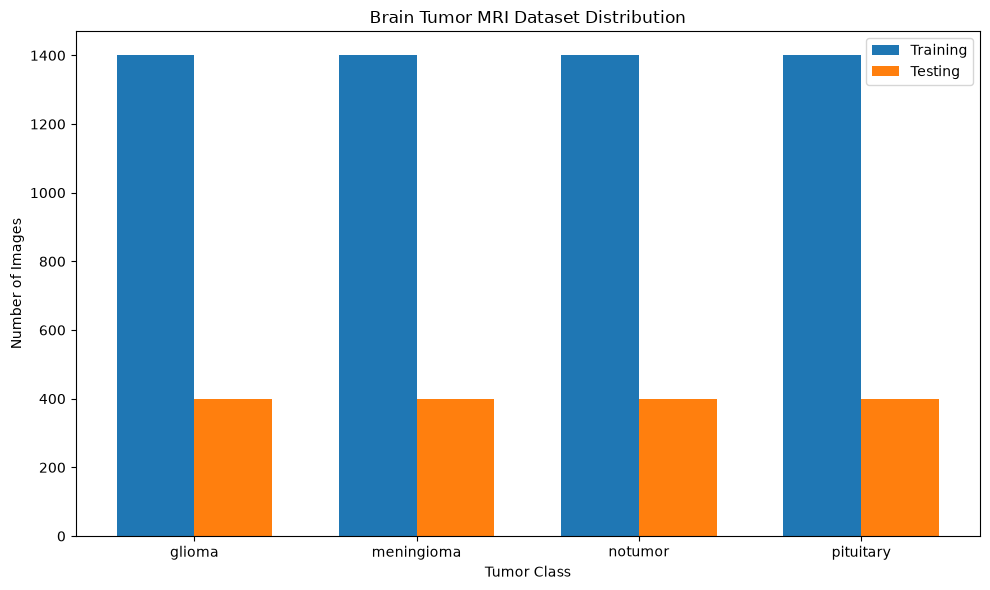


Distribution graph saved to:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\dataset_distribution.png

Total image files found:
7200

Image dimensions:
----------------------------------------
(512, 512): 100 images

Image modes:
----------------------------------------
L: 85 images
RGB: 15 images


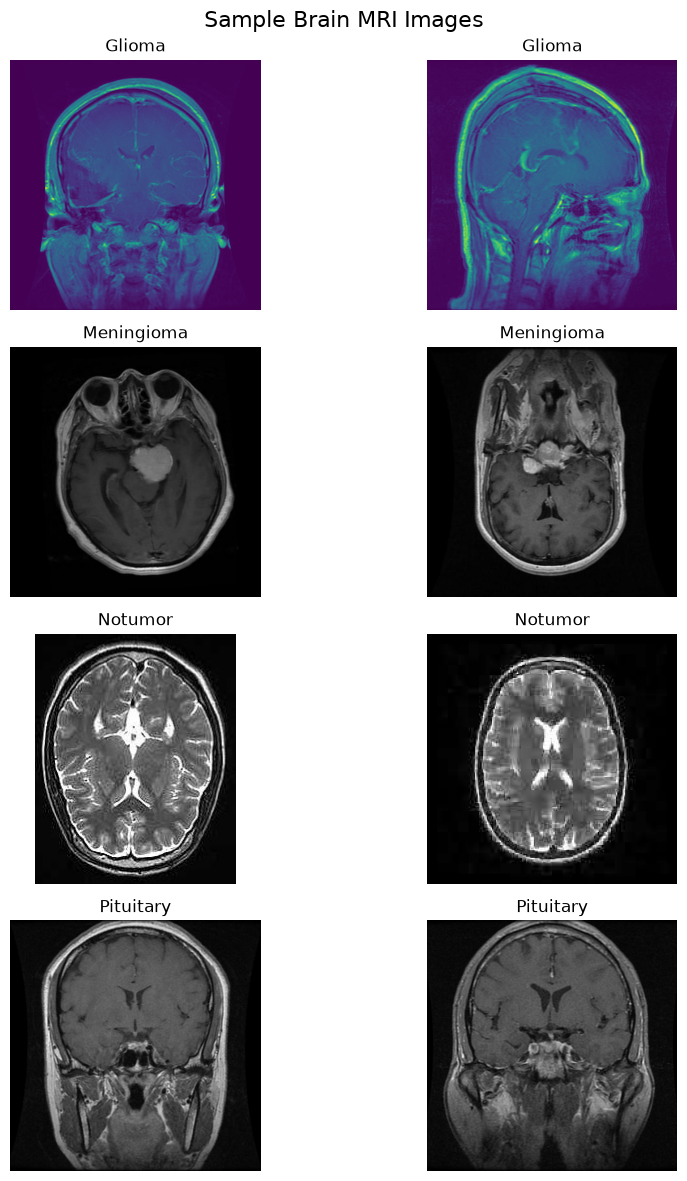


Sample image figure saved to:
c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\sample_mri_images.png

Corrupted image check
Images checked : 7200
Corrupted      : 0
No corrupted images detected.


DATASET EXPLORATION COMPLETED
Project root : c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection
Training     : c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Training
Testing      : c:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Testing
Classes      : ['glioma', 'meningioma', 'notumor', 'pituitary']
Training     : 5600 images
Testing      : 1600 images
Total        : 7200 images
Corrupted    : 0 images

Next notebook:
02_data_preprocessing.ipynb


In [ ]:
# Dataset Exploration

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf


# FIND PROJECT ROOT

CURRENT_DIR = Path.cwd()

print("Current notebook directory:")
print(CURRENT_DIR)


# Search current directory and parents for the data folder
PROJECT_ROOT = None

for path in [CURRENT_DIR] + list(CURRENT_DIR.parents):
    if (path / "data" / "raw").exists():
        PROJECT_ROOT = path
        break


if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root containing data/raw.\n"
        "Please check your folder structure."
    )


DATA_ROOT = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


print("\nProject root:")
print(PROJECT_ROOT)

print("\nData root:")
print(DATA_ROOT)

#FIND TRAINING AND TESTING FOLDERS

def find_folder(root, folder_name):

    matches = [
        path
        for path in root.rglob(folder_name)
        if path.is_dir()
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Could not find '{folder_name}' inside:\n{root}"
        )

    return matches[0]


TRAIN_DIR = find_folder(DATA_ROOT, "Training")
TEST_DIR = find_folder(DATA_ROOT, "Testing")


print("\nTraining directory:")
print(TRAIN_DIR)

print("\nTesting directory:")
print(TEST_DIR)

#FIND CLASS NAMES


CLASS_NAMES = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])


print("\nClasses:")
print(CLASS_NAMES)

print("\nNumber of classes:")
print(len(CLASS_NAMES))

# COUNT IMAGES

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}


def get_images(folder):

    return [
        file
        for file in folder.rglob("*")
        if (
            file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )
    ]


train_counts = {}
test_counts = {}


for class_name in CLASS_NAMES:

    train_class_folder = TRAIN_DIR / class_name
    test_class_folder = TEST_DIR / class_name

    train_counts[class_name] = len(
        get_images(train_class_folder)
    )

    test_counts[class_name] = len(
        get_images(test_class_folder)
    )


print("\nTraining image counts:")
print("-" * 40)

for class_name in CLASS_NAMES:
    print(
        f"{class_name:15s}: "
        f"{train_counts[class_name]}"
    )


print("\nTesting image counts:")
print("-" * 40)

for class_name in CLASS_NAMES:
    print(
        f"{class_name:15s}: "
        f"{test_counts[class_name]}"
    )

#DATASET DISTRIBUTION TABLE

distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training": [
        train_counts[c]
        for c in CLASS_NAMES
    ],
    "Testing": [
        test_counts[c]
        for c in CLASS_NAMES
    ]
})


distribution_df["Total"] = (
    distribution_df["Training"]
    + distribution_df["Testing"]
)


print("\nDataset distribution:")
display(distribution_df)

#TOTAL DATASET SIZE
total_training = sum(train_counts.values())
total_testing = sum(test_counts.values())
total_images = total_training + total_testing


print("\nDataset summary")
print("=" * 50)

print(f"Training images : {total_training}")
print(f"Testing images  : {total_testing}")
print(f"Total images    : {total_images}")
print(f"Classes         : {len(CLASS_NAMES)}")

#CLASS DISTRIBUTION GRAPH

plt.figure(figsize=(10, 6))

x = np.arange(len(CLASS_NAMES))
width = 0.35


plt.bar(
    x - width / 2,
    [train_counts[c] for c in CLASS_NAMES],
    width,
    label="Training"
)


plt.bar(
    x + width / 2,
    [test_counts[c] for c in CLASS_NAMES],
    width,
    label="Testing"
)


plt.xticks(
    x,
    CLASS_NAMES
)

plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")

plt.title(
    "Brain Tumor MRI Dataset Distribution"
)

plt.legend()

plt.tight_layout()


distribution_path = (
    FIGURES_DIR /
    "dataset_distribution.png"
)

plt.savefig(
    distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\nDistribution graph saved to:"
)
print(distribution_path)

#IMAGE DIMENSION CHECK

all_images = []

for split_directory in [
    TRAIN_DIR,
    TEST_DIR
]:

    all_images.extend(
        get_images(split_directory)
    )


print("\nTotal image files found:")
print(len(all_images))


# Check first 100 images
sample_for_dimension_check = all_images[:100]

dimensions = []
modes = []


for image_path in sample_for_dimension_check:

    try:

        with Image.open(image_path) as img:

            dimensions.append(img.size)
            modes.append(img.mode)

    except Exception:

        pass


dimension_counts = Counter(dimensions)
mode_counts = Counter(modes)


print("\nImage dimensions:")
print("-" * 40)

for dimension, count in dimension_counts.most_common(10):

    print(
        f"{dimension}: {count} images"
    )


print("\nImage modes:")
print("-" * 40)

for mode, count in mode_counts.items():

    print(
        f"{mode}: {count} images"
    )


# 9. DISPLAY SAMPLE MRI IMAGES

samples_per_class = 2

fig, axes = plt.subplots(
    len(CLASS_NAMES),
    samples_per_class,
    figsize=(10, 12)
)


for row, class_name in enumerate(CLASS_NAMES):

    class_folder = TRAIN_DIR / class_name

    class_images = get_images(class_folder)

    selected_images = class_images[
        :samples_per_class
    ]


    for col in range(samples_per_class):

        ax = axes[row, col]


        if col < len(selected_images):

            image_path = selected_images[col]


            with Image.open(image_path) as img:

                ax.imshow(img)


            ax.set_title(
                class_name.capitalize()
            )


        ax.axis("off")


plt.suptitle(
    "Sample Brain MRI Images",
    fontsize=16
)

plt.tight_layout()


sample_path = (
    FIGURES_DIR /
    "sample_mri_images.png"
)


plt.savefig(
    sample_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\nSample image figure saved to:"
)

print(sample_path)

# CHECK FOR CORRUPTED IMAGES

corrupted_images = []


for image_path in all_images:

    try:

        with Image.open(image_path) as img:

            img.verify()


    except Exception:

        corrupted_images.append(
            image_path
        )


print("\nCorrupted image check")
print("=" * 50)

print(
    f"Images checked : {len(all_images)}"
)

print(
    f"Corrupted      : {len(corrupted_images)}"
)


if corrupted_images:

    print("\nCorrupted files:")

    for file in corrupted_images[:20]:

        print(file)

else:

    print(
        "No corrupted images detected."
    )


#FINAL SUMMARY


print("\n")
print("=" * 60)
print("DATASET EXPLORATION COMPLETED")
print("=" * 60)

print(
    f"Project root : {PROJECT_ROOT}"
)

print(
    f"Training     : {TRAIN_DIR}"
)

print(
    f"Testing      : {TEST_DIR}"
)

print(
    f"Classes      : {CLASS_NAMES}"
)

print(
    f"Training     : {total_training} images"
)

print(
    f"Testing      : {total_testing} images"
)

print(
    f"Total        : {total_images} images"
)

print(
    f"Corrupted    : {len(corrupted_images)} images"
)

print("\nNext notebook:")
print("02_data_preprocessing.ipynb")